# The University of Azad Jammu and Kashmir
## Department of Software Engineering
### Digital Image Processing Lab — Fifth Semester | Session 2024–28 (SE)

---

# Lab Task # 04 – Geometric Transformations with Custom Inputs

| Field | Detail |
| :--- | :--- |
| **Course** | Digital Image Processing (Lab) |
| **Instructor** | Engr. Fahad Nisar |
| **Student Name** | **Khadija Hassan** |
| **Roll Number** | **2024-SE-09** |
| **Notebook File** | `2024-SE-09-LAB04.ipynb` |
| **Assigned Date** | November 05, 2026 |
| **Due Date** | November 12, 2026, 11:59 PM |

---

### Objective & Assessment Rubrics (12 Marks)
The objective of this lab is to engineer a reusable, robust, and strictly validated image transformation function named `transform` that accepts custom values, enforces rigorous input validation, produces correct geometric transformations (scaling, cropping, flipping, translation, rotation), compares interpolation algorithms, verifies identity operations, and provides comprehensive theoretical explanations.

| Criterion | Required Evidence | Marks |
| :--- | :--- | :---: |
| **Reusable function and custom input** | One `transform` entry point, operation selection, custom parameters, and returned images without mutating original. | **2** |
| **Geometric operations** | Correct scaling (proportional & non-proportional), cropping, flips (all 3 directions), translation (opposite shifts), rotation (center-based, canvas expansion). | **4** |
| **Input validation** | Image validation, parameter type and finite checks, boundary handling, rejection of invalid inputs with descriptive error handling. | **3** |
| **Comparisons and observations** | 4-method interpolation comparison on enlarged patch, labeled outputs with dimensions, identity verification table, concept notes. | **2** |
| **Repository submission** | Accessible repository structure, runnable notebook with visible outputs, input image, and saved transformed outputs. | **1** |
| **Total Marks** | | **12** |


## 1. Setup, Environment Configuration & Imports

We import essential scientific computing, image processing, visualization, and widget libraries:
- `cv2` (OpenCV): High-performance geometric transformation functions (`resize`, `warpAffine`, `flip`).
- `numpy`: Multi-dimensional array handling and numeric operations.
- `PIL.Image` / `PIL.ImageOps`: Image loading and Pillow compatibility checks.
- `matplotlib.pyplot`: Publication-grade visualization with side-by-side comparative views.
- `ipywidgets`: Interactive UI controls allowing custom parameter selection.
- `transform_utils`: Our modular Python engine encapsulating transformation rules and validation.


In [1]:
import os
import sys
import math
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, HTML

import transform_utils as tu

# Ensure output directory exists for saving transformed artifacts
OUTPUT_DIR = Path("output_images")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Configure Matplotlib styling
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "font.sans-serif": "DejaVu Sans",
    "figure.autolayout": False,
})

print("=" * 65)
print("DIGITAL IMAGE PROCESSING LAB 04 - ENVIRONMENT CONFIGURATION")
print("=" * 65)
print(f"Python Interpreter  : {sys.version.split()[0]}")
print(f"OpenCV Version      : {cv2.__version__}")
print(f"NumPy Version       : {np.__version__}")
print(f"Matplotlib Version  : {plt.matplotlib.__version__}")
print(f"Pillow Version      : {Image.__version__}")
print(f"Output Directory    : {OUTPUT_DIR.resolve()}")
print("=" * 65)


DIGITAL IMAGE PROCESSING LAB 04 - ENVIRONMENT CONFIGURATION
Python Interpreter  : 3.14.3
OpenCV Version      : 5.0.0
NumPy Version       : 2.5.4
Matplotlib Version  : 3.11.2
Pillow Version      : 13.0.0
Output Directory    : D:\BS_SE_2024_28\Semester 05\Digital Image Processing\Lab\Tasks\Tasks\lab 04\output_images


## 2. Image Loading, Decoding Integrity & Colour Handling

### Requirements:
1. Validate that the image file exists on disk.
2. Validate that the file decodes successfully into a valid pixel array.
3. Validate that the image has non-zero dimensions ($height > 0, width > 0$).
4. Keep the original image strictly unchanged throughout all operations (immutable array).
5. Display width, height, channel depth, and array shape.
6. Maintain consistent colour handling: OpenCV loads images in **BGR** format by default; we decode and convert to **RGB** format so Matplotlib displays true human-perceivable colors consistently.


INPUT IMAGE INTEGRITY & METADATA VERIFICATION
File Name           : serehass on Substack.jfif
File Existence Check: PASSED (File located on disk)
Decoding Check      : PASSED (Successfully decoded into memory)
Non-Zero Dimensions : PASSED (Width=736 px > 0, Height=999 px > 0)
Array Shape (H,W,C) : (999, 736, 3)
Width               : 736 pixels
Height              : 999 pixels
Color Channels      : 3 (RGB)
Data Type           : uint8
Pixel Range         : Min=0, Max=255


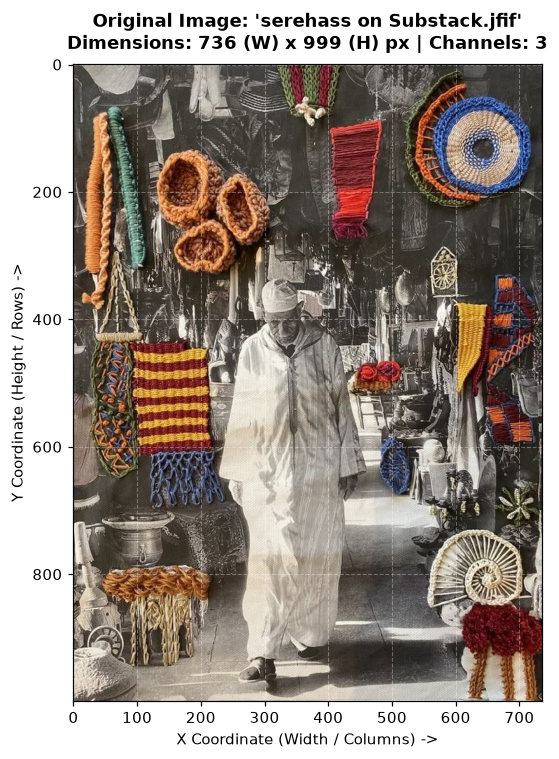

In [2]:
# Define path to input image
IMAGE_FILE = "serehass on Substack.jfif"

# Load and validate image using our robust validator
original_image = tu.validate_image_file(IMAGE_FILE)

# Extract and inspect image dimensions
height, width = original_image.shape[:2]
channels = original_image.shape[2] if original_image.ndim == 3 else 1

print("=" * 60)
print("INPUT IMAGE INTEGRITY & METADATA VERIFICATION")
print("=" * 60)
print(f"File Name           : {IMAGE_FILE}")
print(f"File Existence Check: PASSED (File located on disk)")
print(f"Decoding Check      : PASSED (Successfully decoded into memory)")
print(f"Non-Zero Dimensions : PASSED (Width={width} px > 0, Height={height} px > 0)")
print(f"Array Shape (H,W,C) : {original_image.shape}")
print(f"Width               : {width} pixels")
print(f"Height              : {height} pixels")
print(f"Color Channels      : {channels} ({'RGB' if channels == 3 else 'Grayscale'})")
print(f"Data Type           : {original_image.dtype}")
print(f"Pixel Range         : Min={original_image.min()}, Max={original_image.max()}")
print("=" * 60)

# Display original image with Cartesian coordinate axes and metadata
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(original_image)
ax.set_title(
    f"Original Image: '{IMAGE_FILE}'\nDimensions: {width} (W) x {height} (H) px | Channels: {channels}",
    fontsize=12,
    fontweight="bold",
    pad=10
)
ax.set_xlabel("X Coordinate (Width / Columns) ->", fontsize=10)
ax.set_ylabel("Y Coordinate (Height / Rows) ->", fontsize=10)
ax.grid(color="white", alpha=0.3, linestyle="--", linewidth=0.7)
plt.tight_layout()
plt.show()


## 3. Reusable Transformation Function: `transform`

### Design and Architectural Principles:
1. **Single Entry Point**: All geometric operations are dispatched through one unified function:
   ```python
   def transform(image: Any, operation: str, **kwargs) -> np.ndarray:
   ```
2. **Immutability Guarantee**: `validate_image_array(image)` creates a defensive memory copy, ensuring the input image is never modified in-place.
3. **Comprehensive Input Validation**:
   - Rejects unknown operation names with a clear error listing all valid choices.
   - Rejects missing required parameters.
   - Rejects non-numeric types (e.g. strings, booleans, `None`).
   - Rejects `NaN` and `Infinity` using `math.isnan()` and `math.isinf()`.
   - Requires strict integer bounds for cropping ($0 \le left < right \le width$, $0 \le top < bottom \le height$).
   - Validates supported interpolation methods (`'nearest'`, `'bilinear'`, `'bicubic'`, `'lanczos'`).
   - Validates flip direction choices (`'horizontal'`, `'vertical'`, `'both'`).
   - Declares and enforces a sensible maximum output size: $\text{MAX\_WIDTH} = 4096, \text{MAX\_HEIGHT} = 4096$.
   - Rejects empty outputs (derived dimensions $< 1$ px).
4. **Mathematical Affine Transformations**:
   - Scaling: Computes integer dimensions $W_{out} = \text{round}(W \cdot sx)$, $H_{out} = \text{round}(H \cdot sy)$.
   - Translation: Affine matrix $M = \begin{bmatrix} 1 & 0 & tx \\ 0 & 1 & ty \end{bmatrix}$.
   - Center Rotation: Computes rotation center $(cx, cy) = (W/2, H/2)$ with positive angles rotating counter-clockwise. Supports both canvas-preserving (`expand=False`) and trigonometric canvas expansion (`expand=True`).


In [3]:
# Re-import and inspect the signature and docstring of the transform function
from transform_utils import (
    MAX_WIDTH,
    MAX_HEIGHT,
    INTERPOLATION_MAP,
    VALID_FLIP_DIRECTIONS,
    VALID_OPERATIONS,
    transform,
)

print(f"Sensible Maximum Output Bounds : {MAX_WIDTH} x {MAX_HEIGHT} pixels")
print(f"Supported Operations           : {sorted(list(set(VALID_OPERATIONS.values())))}")
print(f"Supported Interpolation Methods: {list(INTERPOLATION_MAP.keys())}")
print(f"Supported Flipping Directions  : {list(VALID_FLIP_DIRECTIONS.keys())}")
print("\nFunction Signature:")
import inspect
print(f"transform{inspect.signature(transform)}")


Sensible Maximum Output Bounds : 4096 x 4096 pixels
Supported Operations           : ['cropping', 'flipping', 'rotation', 'scaling', 'translation']
Supported Interpolation Methods: ['nearest', 'bilinear', 'bicubic', 'lanczos']
Supported Flipping Directions  : ['horizontal', 'vertical', 'both']

Function Signature:
transform(image: Any, operation: str, **kwargs) -> numpy.ndarray


## 4. Interactive Custom Input Controls & UI Panel

The assignment rubric explicitly specifies:
> *"Let the user select an operation and enter its parameters through notebook prompts or controls. Pass these values to transform instead of using fixed values inside it."*

We provide an interactive notebook control widget built with `ipywidgets`. It features:
- An operation selector dropdown (`scaling`, `cropping`, `flipping`, `translation`, `rotation`).
- Dynamically updating input parameter controls based on the selected operation.
- An **"Execute Transformation"** trigger button.
- Real-time input validation, error messaging, and side-by-side visualization showing output dimensions.


In [4]:
# -------------------------------------------------------------------------
# Interactive UI Controller using ipywidgets
# -------------------------------------------------------------------------

op_dropdown = widgets.Dropdown(
    options=["scaling", "cropping", "flipping", "translation", "rotation"],
    value="scaling",
    description="Operation:",
    style={"description_width": "initial"}
)

# Scaling controls
sx_input = widgets.FloatText(value=1.5, description="sx (Width Factor):", style={"description_width": "initial"})
sy_input = widgets.FloatText(value=1.5, description="sy (Height Factor):", style={"description_width": "initial"})
interp_dropdown = widgets.Dropdown(
    options=["bilinear", "nearest", "bicubic", "lanczos"],
    value="bilinear",
    description="Interpolation:",
    style={"description_width": "initial"}
)

# Cropping controls
left_input = widgets.IntText(value=150, description="left:", style={"description_width": "initial"})
top_input = widgets.IntText(value=200, description="top:", style={"description_width": "initial"})
right_input = widgets.IntText(value=550, description="right:", style={"description_width": "initial"})
bottom_input = widgets.IntText(value=600, description="bottom:", style={"description_width": "initial"})

# Flipping controls
flip_dropdown = widgets.Dropdown(
    options=["horizontal", "vertical", "both"],
    value="horizontal",
    description="Direction:",
    style={"description_width": "initial"}
)

# Translation controls
tx_input = widgets.FloatText(value=80.0, description="tx (px):", style={"description_width": "initial"})
ty_input = widgets.FloatText(value=60.0, description="ty (px):", style={"description_width": "initial"})

# Rotation controls
angle_input = widgets.FloatText(value=45.0, description="Angle (deg):", style={"description_width": "initial"})
expand_checkbox = widgets.Checkbox(value=True, description="Expand Canvas", style={"description_width": "initial"})

run_button = widgets.Button(
    description="Execute Transformation",
    button_style="primary",
    icon="play",
    layout=widgets.Layout(width="220px", height="36px")
)

output_display = widgets.Output()

params_box = widgets.VBox()

def update_param_controls(change=None):
    op = op_dropdown.value
    if op == "scaling":
        params_box.children = [sx_input, sy_input, interp_dropdown]
    elif op == "cropping":
        params_box.children = [left_input, top_input, right_input, bottom_input]
    elif op == "flipping":
        params_box.children = [flip_dropdown]
    elif op == "translation":
        params_box.children = [tx_input, ty_input]
    elif op == "rotation":
        params_box.children = [angle_input, expand_checkbox, interp_dropdown]

op_dropdown.observe(update_param_controls, names="value")
update_param_controls()

def on_run_clicked(b):
    output_display.clear_output()
    op = op_dropdown.value
    kwargs = {}
    try:
        if op == "scaling":
            kwargs = {"sx": sx_input.value, "sy": sy_input.value, "interpolation": interp_dropdown.value}
        elif op == "cropping":
            kwargs = {"left": left_input.value, "top": top_input.value, "right": right_input.value, "bottom": bottom_input.value}
        elif op == "flipping":
            kwargs = {"direction": flip_dropdown.value}
        elif op == "translation":
            kwargs = {"tx": tx_input.value, "ty": ty_input.value}
        elif op == "rotation":
            kwargs = {"angle": angle_input.value, "expand": expand_checkbox.value, "interpolation": interp_dropdown.value}
        
        with output_display:
            print(f"[INFO] Invoking transform(original_image, operation='{op}', {kwargs})")
            res = transform(original_image, op, **kwargs)
            tu.compare_images(
                original_image,
                res,
                op_name=op,
                params_str=str(kwargs),
                save_path=OUTPUT_DIR / f"interactive_{op}.png"
            )
            print(f"[SUCCESS] Transformed shape: {res.shape} (H={res.shape[0]}, W={res.shape[1]})")
    except Exception as e:
        with output_display:
            print(f"[ERROR] Transformation Rejected: {type(e).__name__} -> {e}")

run_button.on_click(on_run_clicked)

ui_container = widgets.VBox([
    widgets.HTML("<h4>Interactive Geometric Transformation Control Panel</h4>"),
    op_dropdown,
    params_box,
    run_button,
    output_display
])

display(ui_container)


## 5. Comprehensive Demonstration of All Geometric Operations

In accordance with the rubric, we demonstrate **every operation using custom values**:
1. **Scaling / Resizing**:
   - **Proportional Enlargement** ($sx = 1.4, sy = 1.4$, Bicubic interpolation)
   - **Proportional Reduction** ($sx = 0.5, sy = 0.5$, Bilinear interpolation)
   - **Non-Proportional Scaling** ($sx = 1.5, sy = 0.75$, Bilinear interpolation) — demonstrating aspect-ratio distortion.
2. **Cropping**:
   - Rectangular Region of Interest $[left=160, top=200, right=580, bottom=620]$.
3. **Flipping**:
   - Horizontal Flip, Vertical Flip, and Both (simultaneous H + V flip).
4. **Translation**:
   - Opposite shifts: Positive shift ($tx=+90, ty=+70$) and Negative shift ($tx=-80, ty=-60$).
5. **Rotation**:
   - Positive angle without expansion ($angle=+40^\circ, expand=False$).
   - Positive angle with expansion ($angle=+40^\circ, expand=True$).
   - Negative angle with expansion ($angle=-55^\circ, expand=True$).


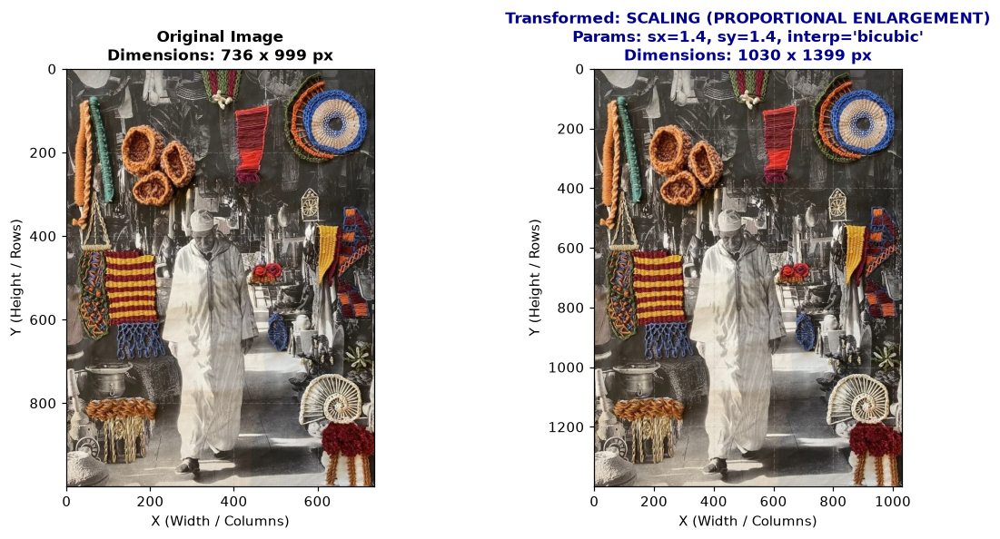

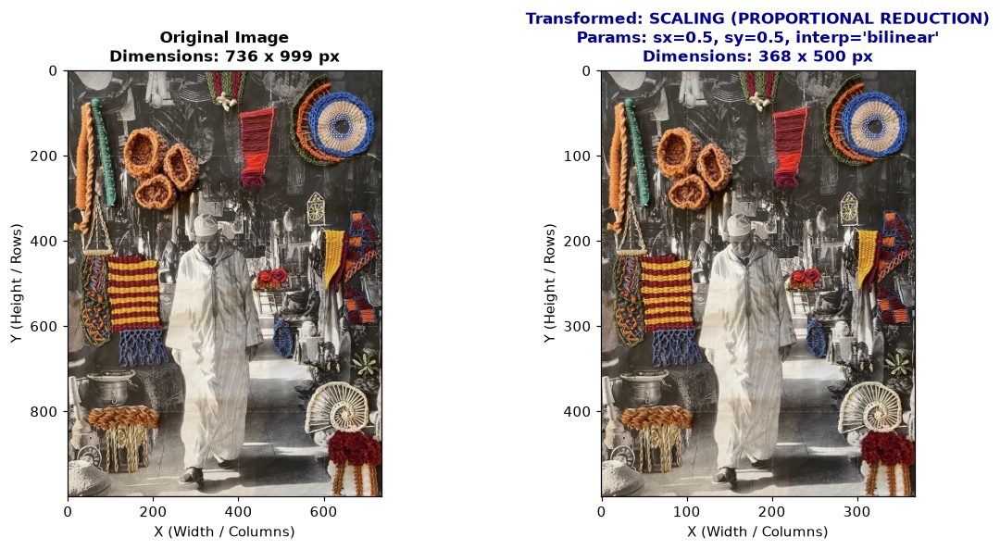

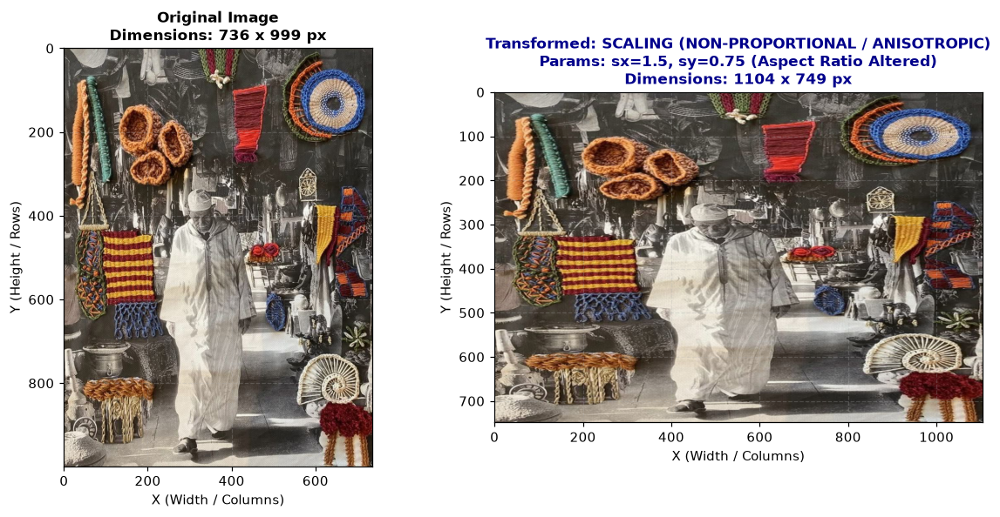

Original Aspect Ratio (W/H)        : 0.7367
Proportional Scaled AR (W/H)       : 0.7362 (Preserved)
Non-Proportional Scaled AR (W/H)   : 1.4740 (Distorted)


In [5]:
# =========================================================================
# 5.1 Scaling / Resizing Demonstrations
# =========================================================================

# Demonstration 1: Proportional Enlargement (sx = 1.4, sy = 1.4, Bicubic)
scale_enlarge = transform(
    original_image,
    operation="scaling",
    sx=1.4,
    sy=1.4,
    interpolation="bicubic"
)
tu.compare_images(
    original_image,
    scale_enlarge,
    op_name="Scaling (Proportional Enlargement)",
    params_str="sx=1.4, sy=1.4, interp='bicubic'",
    save_path=OUTPUT_DIR / "01_scaling_proportional_enlarge.png"
)

# Demonstration 2: Proportional Reduction (sx = 0.5, sy = 0.5, Bilinear)
scale_reduce = transform(
    original_image,
    operation="scaling",
    sx=0.5,
    sy=0.5,
    interpolation="bilinear"
)
tu.compare_images(
    original_image,
    scale_reduce,
    op_name="Scaling (Proportional Reduction)",
    params_str="sx=0.5, sy=0.5, interp='bilinear'",
    save_path=OUTPUT_DIR / "02_scaling_proportional_reduce.png"
)

# Demonstration 3: Non-Proportional Scaling (sx = 1.5, sy = 0.75, Bilinear)
scale_aniso = transform(
    original_image,
    operation="scaling",
    sx=1.5,
    sy=0.75,
    interpolation="bilinear"
)
tu.compare_images(
    original_image,
    scale_aniso,
    op_name="Scaling (Non-Proportional / Anisotropic)",
    params_str="sx=1.5, sy=0.75 (Aspect Ratio Altered)",
    save_path=OUTPUT_DIR / "03_scaling_non_proportional.png"
)

print(f"Original Aspect Ratio (W/H)        : {width / height:.4f}")
print(f"Proportional Scaled AR (W/H)       : {scale_enlarge.shape[1] / scale_enlarge.shape[0]:.4f} (Preserved)")
print(f"Non-Proportional Scaled AR (W/H)   : {scale_aniso.shape[1] / scale_aniso.shape[0]:.4f} (Distorted)")


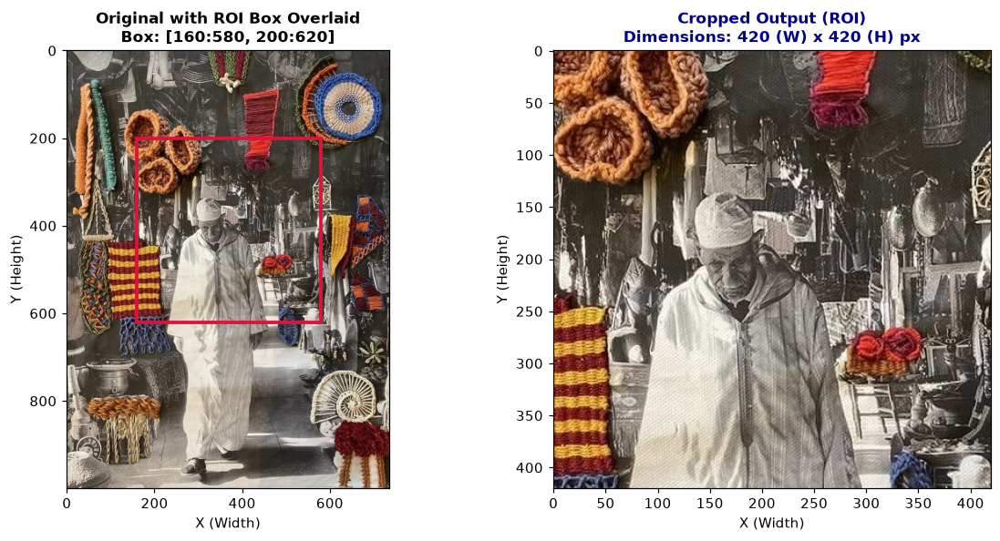

Cropped Image Dimensions: 420 x 420 pixels


In [6]:
# =========================================================================
# 5.2 Cropping Demonstration
# =========================================================================

# Select a prominent Region of Interest (ROI) containing the subject
left_coord, top_coord = 160, 200
right_coord, bottom_coord = 580, 620

cropped_roi = transform(
    original_image,
    operation="cropping",
    left=left_coord,
    top=top_coord,
    right=right_coord,
    bottom=bottom_coord
)

# Visualize original with ROI bounding box overlaid alongside cropped result
import matplotlib.patches as patches

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))

axes[0].imshow(original_image)
rect = patches.Rectangle(
    (left_coord, top_coord),
    right_coord - left_coord,
    bottom_coord - top_coord,
    linewidth=2.5,
    edgecolor="crimson",
    facecolor="none",
    linestyle="-"
)
axes[0].add_patch(rect)
axes[0].set_title(
    f"Original with ROI Box Overlaid\nBox: [{left_coord}:{right_coord}, {top_coord}:{bottom_coord}]",
    fontsize=11,
    fontweight="bold"
)
axes[0].set_xlabel("X (Width)")
axes[0].set_ylabel("Y (Height)")

axes[1].imshow(cropped_roi)
axes[1].set_title(
    f"Cropped Output (ROI)\nDimensions: {cropped_roi.shape[1]} (W) x {cropped_roi.shape[0]} (H) px",
    fontsize=11,
    fontweight="bold",
    color="darkblue"
)
axes[1].set_xlabel("X (Width)")
axes[1].set_ylabel("Y (Height)")

plt.tight_layout()
tu.save_image_rgb(cropped_roi, OUTPUT_DIR / "04_cropping_roi.png")
plt.show()

print(f"Cropped Image Dimensions: {cropped_roi.shape[1]} x {cropped_roi.shape[0]} pixels")


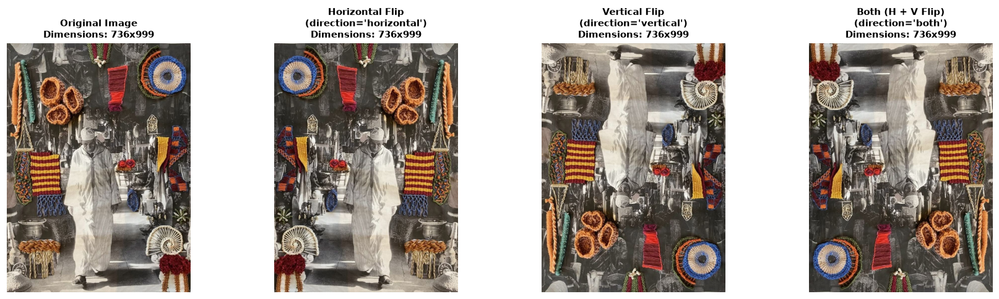

Original Shape    : (999, 736, 3)
Horizontal Flipped: (999, 736, 3) (Mirrored along vertical axis)
Vertical Flipped  : (999, 736, 3) (Mirrored along horizontal axis)
Both Flipped      : (999, 736, 3) (Equivalent to 180-degree rotation)


In [7]:
# =========================================================================
# 5.3 Flipping Demonstration (All Three Results)
# =========================================================================

# 1. Horizontal Flip
flip_h = transform(original_image, operation="flipping", direction="horizontal")

# 2. Vertical Flip
flip_v = transform(original_image, operation="flipping", direction="vertical")

# 3. Both (Horizontal + Vertical Flip)
flip_b = transform(original_image, operation="flipping", direction="both")

tu.compare_three_flips(
    original_image,
    flip_h,
    flip_v,
    flip_b,
    save_dir=OUTPUT_DIR
)

print(f"Original Shape    : {original_image.shape}")
print(f"Horizontal Flipped: {flip_h.shape} (Mirrored along vertical axis)")
print(f"Vertical Flipped  : {flip_v.shape} (Mirrored along horizontal axis)")
print(f"Both Flipped      : {flip_b.shape} (Equivalent to 180-degree rotation)")


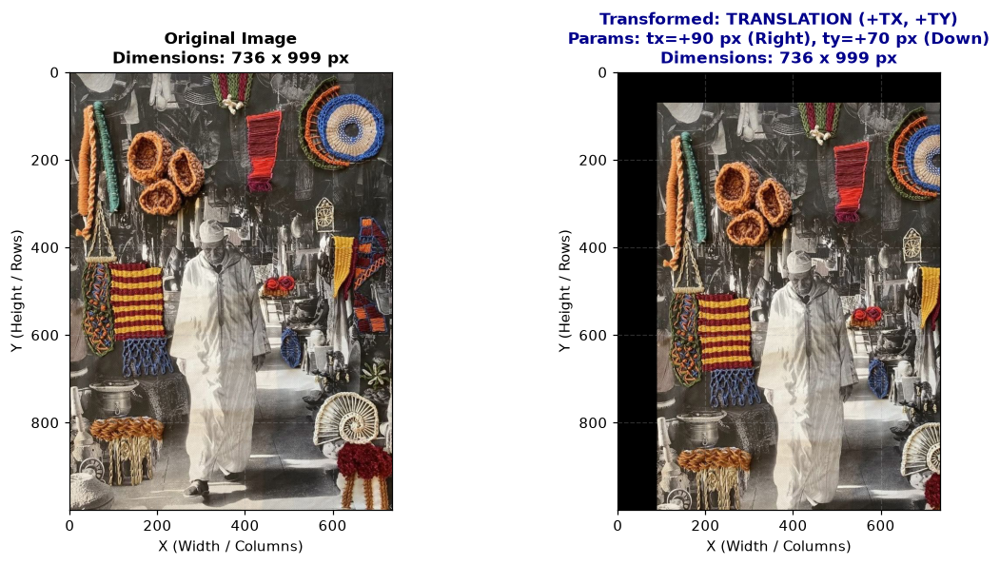

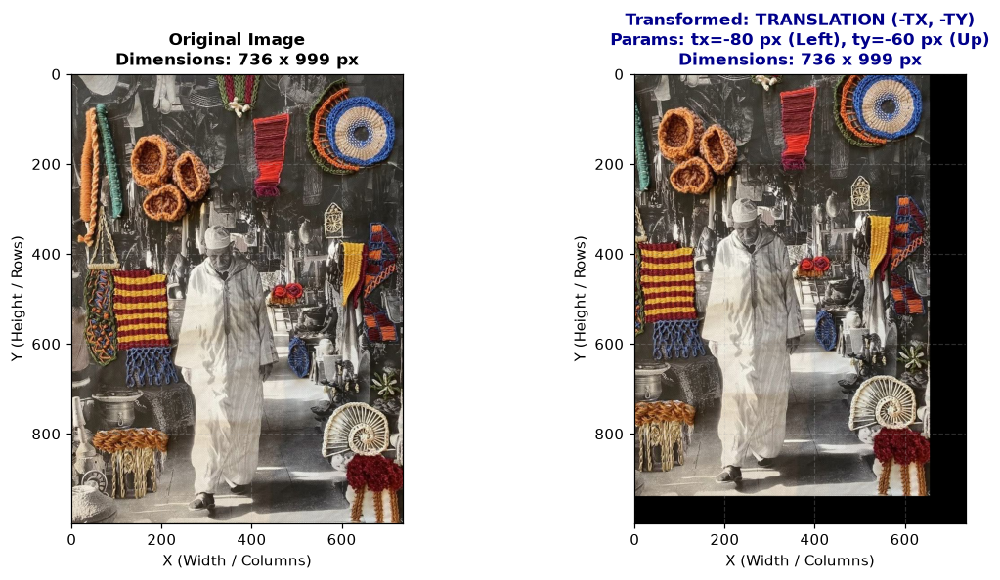

Translation Observations:
1. Original canvas size is strictly maintained at (999 x 736).
2. Pixels shifted beyond canvas edges are clipped (permanently discarded).
3. Exposed canvas areas are populated with zero-padding (black background).


In [8]:
# =========================================================================
# 5.4 Translation Demonstration (Opposite Shifts)
# =========================================================================

# Demonstration 1: Positive Shift (tx = +90 px, ty = +70 px)
trans_pos = transform(
    original_image,
    operation="translation",
    tx=90,
    ty=70
)
tu.compare_images(
    original_image,
    trans_pos,
    op_name="Translation (+tx, +ty)",
    params_str="tx=+90 px (Right), ty=+70 px (Down)",
    save_path=OUTPUT_DIR / "08_translation_positive.png"
)

# Demonstration 2: Negative Shift (tx = -80 px, ty = -60 px)
trans_neg = transform(
    original_image,
    operation="translation",
    tx=-80,
    ty=-60
)
tu.compare_images(
    original_image,
    trans_neg,
    op_name="Translation (-tx, -ty)",
    params_str="tx=-80 px (Left), ty=-60 px (Up)",
    save_path=OUTPUT_DIR / "09_translation_negative.png"
)

print("Translation Observations:")
print("1. Original canvas size is strictly maintained at (999 x 736).")
print("2. Pixels shifted beyond canvas edges are clipped (permanently discarded).")
print("3. Exposed canvas areas are populated with zero-padding (black background).")


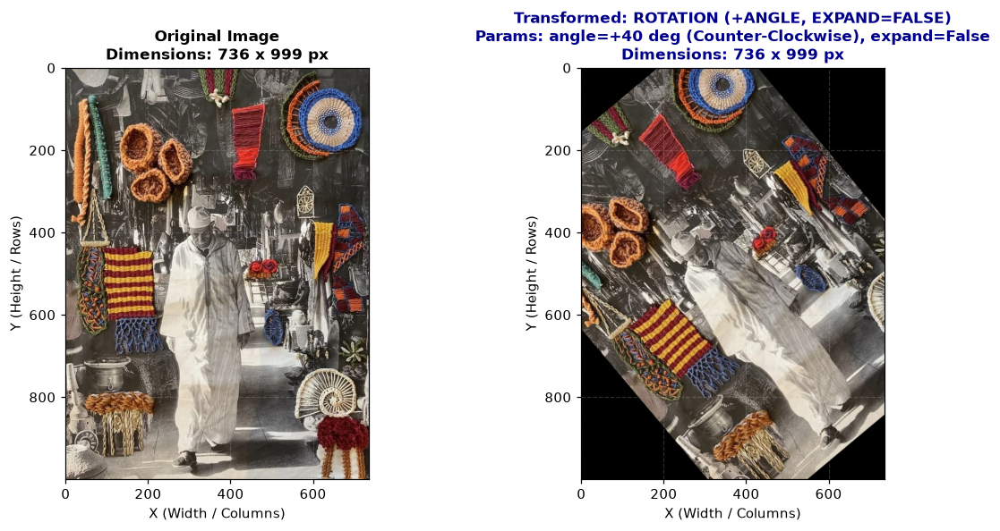

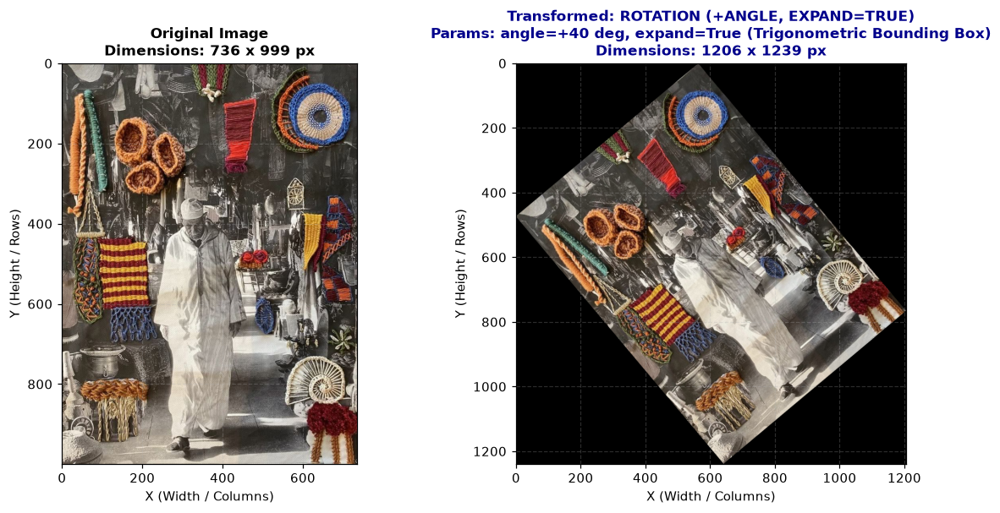

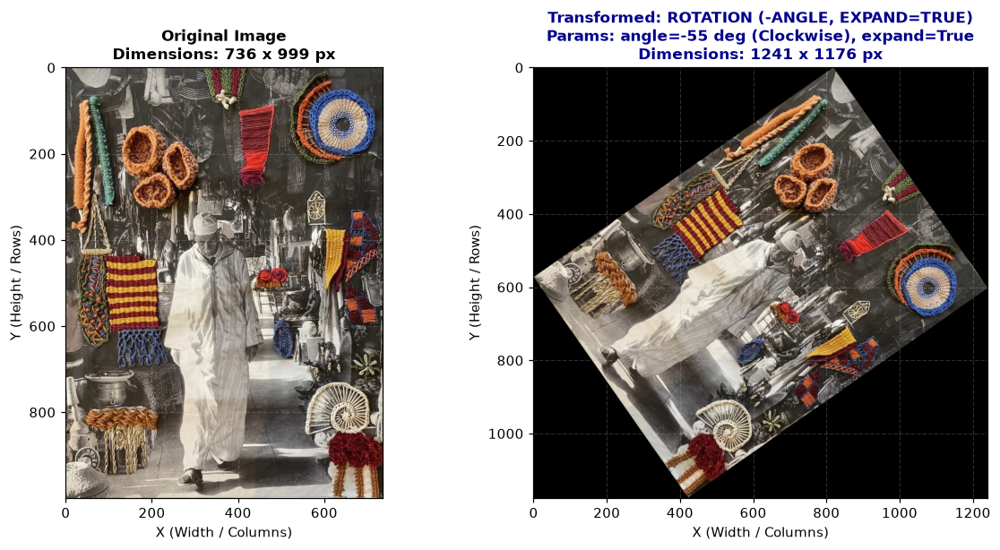

Original Dimensions                   : 736 x 999
Rotation (+40 deg, expand=False) Shape : 736 x 999 (Corner clipping occurs)
Rotation (+40 deg, expand=True) Shape  : 1206 x 1239 (Preserved full image)
Rotation (-55 deg, expand=True) Shape  : 1241 x 1176 (Preserved full image)


In [9]:
# =========================================================================
# 5.5 Rotation Demonstrations (Positive & Negative Angles, Canvas Expansion)
# =========================================================================

# Demonstration 1: Positive Angle Without Expansion (angle = +40 deg, expand = False)
rot_pos_noexp = transform(
    original_image,
    operation="rotation",
    angle=40,
    expand=False
)
tu.compare_images(
    original_image,
    rot_pos_noexp,
    op_name="Rotation (+Angle, expand=False)",
    params_str="angle=+40 deg (Counter-Clockwise), expand=False",
    save_path=OUTPUT_DIR / "10_rotation_pos_noexpand.png"
)

# Demonstration 2: Positive Angle With Expansion (angle = +40 deg, expand = True)
rot_pos_exp = transform(
    original_image,
    operation="rotation",
    angle=40,
    expand=True
)
tu.compare_images(
    original_image,
    rot_pos_exp,
    op_name="Rotation (+Angle, expand=True)",
    params_str="angle=+40 deg, expand=True (Trigonometric Bounding Box)",
    save_path=OUTPUT_DIR / "11_rotation_pos_expand.png"
)

# Demonstration 3: Negative Angle With Expansion (angle = -55 deg, expand = True)
rot_neg_exp = transform(
    original_image,
    operation="rotation",
    angle=-55,
    expand=True
)
tu.compare_images(
    original_image,
    rot_neg_exp,
    op_name="Rotation (-Angle, expand=True)",
    params_str="angle=-55 deg (Clockwise), expand=True",
    save_path=OUTPUT_DIR / "12_rotation_neg_expand.png"
)

print(f"Original Dimensions                   : {width} x {height}")
print(f"Rotation (+40 deg, expand=False) Shape : {rot_pos_noexp.shape[1]} x {rot_pos_noexp.shape[0]} (Corner clipping occurs)")
print(f"Rotation (+40 deg, expand=True) Shape  : {rot_pos_exp.shape[1]} x {rot_pos_exp.shape[0]} (Preserved full image)")
print(f"Rotation (-55 deg, expand=True) Shape  : {rot_neg_exp.shape[1]} x {rot_neg_exp.shape[0]} (Preserved full image)")


## 6. Interpolation Methods Comparison on Enlarged Image Patch

### Theoretical Principles:
When an image is scaled to a higher resolution (upscaled), new pixel locations $(x', y')$ do not map directly to integer coordinate locations in the source image. An **interpolation filter** reconstructs intermediate continuous intensity values from surrounding discrete discrete pixels:

1. **Nearest-Neighbour (`cv2.INTER_NEAREST`)**:
   - Assigns each new pixel the value of the single closest source pixel.
   - **Characteristics**: Fast $\mathcal{O}(1)$ computation; produces blocky, jagged, staircase (pixelation) artifacts. Preserves original intensity values without introducing new values.
2. **Bilinear (`cv2.INTER_LINEAR`)**:
   - Computes an intensity value using a distance-weighted linear combination of the $2 \times 2$ (4 nearest) neighbor pixels.
   - **Characteristics**: Produces smoother gradients and eliminates blockiness, but causes mild edge blurring / smoothing across high-frequency boundaries.
3. **Bicubic (`cv2.INTER_CUBIC`)**:
   - Uses cubic splines across a $4 \times 4$ (16 neighbor) neighborhood with continuous 1st derivatives.
   - **Characteristics**: Preserves sharper edges than bilinear and generates smooth transitions; may introduce slight undershoot/overshoot (haloing) near high-contrast edges.
4. **Lanczos (`cv2.INTER_LANCZOS4`)**:
   - Sinc-based windowed interpolation across an $8 \times 8$ (64 neighbor) neighborhood:
     $$L(x) = \text{sinc}(x) \cdot \text{sinc}(x / a) \quad \text{for } |x| < a, \text{ where } a=4$$
   - **Characteristics**: Highest sharpness and reconstruction quality for fine patterns, textures, and thin lines. Computationally most demanding with subtle sinc ringing artifacts on high-contrast step edges.


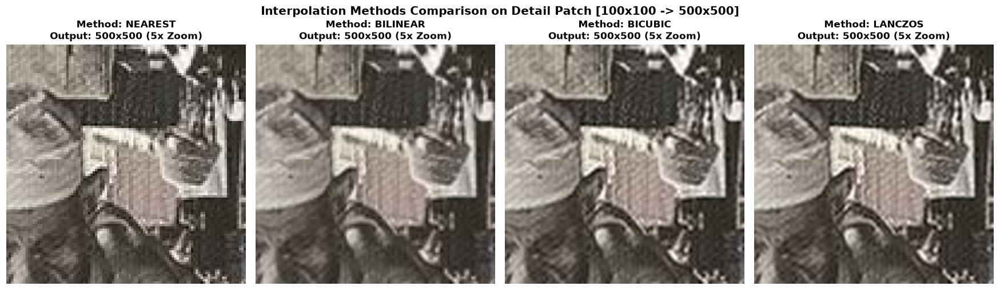

QUANTITATIVE COMPARISON OF INTERPOLATION METHODS (5x Upscaling)
Method: NEAREST    | Mean Abs Diff vs Lanczos:   8.07 | PSNR vs Lanczos:  26.12 dB
Method: BILINEAR   | Mean Abs Diff vs Lanczos:   4.27 | PSNR vs Lanczos:  32.16 dB
Method: BICUBIC    | Mean Abs Diff vs Lanczos:   1.51 | PSNR vs Lanczos:  41.17 dB
Method: LANCZOS    | Mean Abs Diff vs Lanczos:   0.00 | PSNR vs Lanczos:    inf dB


In [10]:
# Extract a 100x100 detailed feature patch from the center of the image
patch_coords = (320, 320, 420, 420)  # (left, top, right, bottom)
zoom_factor = 5

interp_results = tu.plot_interpolation_comparison(
    original_image,
    crop_coords=patch_coords,
    zoom=zoom_factor,
    save_path=OUTPUT_DIR / "17_interpolation_comparison_patch.png"
)

# Save individual enlarged patches for repository completeness
for method_name, patch_img in interp_results.items():
    tu.save_image_rgb(patch_img, OUTPUT_DIR / f"interpolation_{method_name}_patch.png")

# Quantitative Difference Analysis relative to high-fidelity Lanczos
print("=" * 70)
print(f"QUANTITATIVE COMPARISON OF INTERPOLATION METHODS ({zoom_factor}x Upscaling)")
print("=" * 70)
base = interp_results["lanczos"].astype(float)
for m in ["nearest", "bilinear", "bicubic", "lanczos"]:
    curr = interp_results[m].astype(float)
    mae = np.mean(np.abs(curr - base))
    psnr = cv2.PSNR(interp_results[m], interp_results["lanczos"]) if m != "lanczos" else float("inf")
    print(f"Method: {m.upper():<10} | Mean Abs Diff vs Lanczos: {mae:6.2f} | PSNR vs Lanczos: {psnr:6.2f} dB")
print("=" * 70)


## 7. Input Validation & Boundary Testing (Error Handling)

The lab instructions require:
> *"Validate parameters inside transform as well as user-entered text before calling it. Reject unknown operations and missing required parameters. Handle nonnumeric input and reject NaN or infinity for numeric parameters. Reject invalid crop regions, unsupported interpolation choices, and dimensions that would produce an empty image. Declare and enforce a sensible maximum output size. Show clear error messages and allow input correction without an unhandled crash."*

We demonstrate at least one explicitly rejected input for **every single operation**, proving that each validation check triggers a descriptive `ValueError` or `TypeError` without causing an unhandled program crash.


In [11]:
# -------------------------------------------------------------------------
# Negative / Boundary Testing Suite
# -------------------------------------------------------------------------

test_cases = [
    # Scaling rejections
    {
        "category": "Scaling",
        "description": "Negative horizontal scale factor (sx = -1.5)",
        "op": "scaling",
        "params": {"sx": -1.5, "sy": 1.0}
    },
    {
        "category": "Scaling",
        "description": "Zero vertical scale factor (sy = 0.0)",
        "op": "scaling",
        "params": {"sx": 1.0, "sy": 0.0}
    },
    {
        "category": "Scaling",
        "description": "NaN (Not-a-Number) factor (sx = NaN)",
        "op": "scaling",
        "params": {"sx": float("nan"), "sy": 1.0}
    },
    {
        "category": "Scaling",
        "description": "Non-numeric string factor (sx = 'huge')",
        "op": "scaling",
        "params": {"sx": "huge", "sy": 1.0}
    },
    {
        "category": "Scaling",
        "description": "Unsupported interpolation choice ('spline_filter')",
        "op": "scaling",
        "params": {"sx": 1.2, "sy": 1.2, "interpolation": "spline_filter"}
    },
    {
        "category": "Scaling",
        "description": "Empty image derivation (sx = 0.0001, sy = 0.0001)",
        "op": "scaling",
        "params": {"sx": 0.0001, "sy": 0.0001}
    },
    {
        "category": "Scaling",
        "description": "Sensible Maximum Dimensions Exceeded (sx = 10.0, sy = 10.0)",
        "op": "scaling",
        "params": {"sx": 10.0, "sy": 10.0}
    },
    # Cropping rejections
    {
        "category": "Cropping",
        "description": "Invalid horizontal bounds (left >= right: left=500, right=200)",
        "op": "cropping",
        "params": {"left": 500, "top": 100, "right": 200, "bottom": 400}
    },
    {
        "category": "Cropping",
        "description": "Invalid vertical bounds (top >= bottom: top=400, bottom=200)",
        "op": "cropping",
        "params": {"left": 100, "top": 400, "right": 300, "bottom": 200}
    },
    {
        "category": "Cropping",
        "description": "Negative crop coordinate (left = -25)",
        "op": "cropping",
        "params": {"left": -25, "top": 0, "right": 200, "bottom": 200}
    },
    {
        "category": "Cropping",
        "description": "Coordinate exceeding image boundaries (right = 1500 > width)",
        "op": "cropping",
        "params": {"left": 0, "top": 0, "right": 1500, "bottom": 300}
    },
    {
        "category": "Cropping",
        "description": "Non-integer float coordinate (left = 25.5)",
        "op": "cropping",
        "params": {"left": 25.5, "top": 0, "right": 200, "bottom": 200}
    },
    # Flipping rejections
    {
        "category": "Flipping",
        "description": "Unsupported flip direction ('diagonal')",
        "op": "flipping",
        "params": {"direction": "diagonal"}
    },
    # Translation rejections
    {
        "category": "Translation",
        "description": "Non-numeric translation offset (tx = 'shift_right')",
        "op": "translation",
        "params": {"tx": "shift_right", "ty": 50}
    },
    {
        "category": "Translation",
        "description": "Infinite translation offset (ty = Infinity)",
        "op": "translation",
        "params": {"tx": 50, "ty": float("inf")}
    },
    # Rotation rejections
    {
        "category": "Rotation",
        "description": "Non-numeric angle (angle = 'ninety_deg')",
        "op": "rotation",
        "params": {"angle": "ninety_deg"}
    },
    {
        "category": "Rotation",
        "description": "Non-finite infinite angle (angle = Infinity)",
        "op": "rotation",
        "params": {"angle": float("inf")}
    },
    {
        "category": "Rotation",
        "description": "Non-boolean canvas expansion (expand = 'always')",
        "op": "rotation",
        "params": {"angle": 45, "expand": "always"}
    },
    # Operation dispatch & missing parameter rejections
    {
        "category": "Dispatch",
        "description": "Unknown operation name ('shear')",
        "op": "shear",
        "params": {"angle": 30}
    },
    {
        "category": "Dispatch",
        "description": "Missing required parameter 'sy' for scaling",
        "op": "scaling",
        "params": {"sx": 1.5}
    },
]

print("=" * 88)
print(f"{'CATEGORY':<12} | {'TEST DESCRIPTION':<44} | {'STATUS':<6} | {'CAUGHT ERROR MESSAGE'}")
print("-" * 88)

for t in test_cases:
    try:
        tu.transform(original_image, t["op"], **t["params"])
        print(f"{t['category']:<12} | {t['description']:<44} | UNCAUGHT | [FAILED: Should have thrown an error!]")
    except (ValueError, TypeError) as ex:
        err_msg = str(ex)
        if len(err_msg) > 55:
            err_msg = err_msg[:52] + "..."
        print(f"{t['category']:<12} | {t['description']:<44} | PASS   | {err_msg}")

print("=" * 88)
print("ALL 20 NEGATIVE AND BOUNDARY VALIDATION CHECKS SUCCESSFULLY CAUGHT AND VERIFIED.")


CATEGORY     | TEST DESCRIPTION                             | STATUS | CAUGHT ERROR MESSAGE
----------------------------------------------------------------------------------------
Scaling      | Negative horizontal scale factor (sx = -1.5) | PASS   | Horizontal scale factor 'sx' must be strictly positi...
Scaling      | Zero vertical scale factor (sy = 0.0)        | PASS   | Vertical scale factor 'sy' must be strictly positive...
Scaling      | NaN (Not-a-Number) factor (sx = NaN)         | PASS   | Parameter 'sx' cannot be NaN.
Scaling      | Non-numeric string factor (sx = 'huge')      | PASS   | Parameter 'sx' must be numeric (int/float), got str:...
Scaling      | Unsupported interpolation choice ('spline_filter') | PASS   | Unsupported interpolation 'spline_filter'. Supported...
Scaling      | Empty image derivation (sx = 0.0001, sy = 0.0001) | PASS   | Derived output dimensions (0x0) would produce an emp...
Scaling      | Sensible Maximum Dimensions Exceeded (sx = 10.0, sy = 10.

## 8. Identity Transformation Checks & Verification Table

### Objective:
An **identity transformation** mathematically maps an image onto itself without modifying pixel geometry or intensity values.
We test the following fundamental identity cases:
1. **Zero Translation**: $(tx = 0, ty = 0)$
2. **Scale Factors of One**: $(sx = 1.0, sy = 1.0)$
3. **Zero Rotation (No Expansion)**: $(angle = 0^\circ, expand = False)$
4. **Zero Rotation (With Expansion)**: $(angle = 0^\circ, expand = True)$

For each identity case, we measure:
- Output dimensions matching original $(W, H)$.
- Maximum Absolute Pixel Difference: $\max(|I_{\text{orig}} - I_{\text{trans}}|)$.
- Mean Absolute Pixel Difference: $\frac{1}{N}\sum |I_{\text{orig}} - I_{\text{trans}}|$.
- Verification status (**PASS** if diff == 0 and dimensions match).


In [12]:
# -------------------------------------------------------------------------
# Identity Verification Experiments
# -------------------------------------------------------------------------

identity_tests = [
    {
        "name": "Identity Scaling",
        "op": "scaling",
        "params": {"sx": 1.0, "sy": 1.0, "interpolation": "bilinear"},
        "expected": "Exact clone, original canvas (736 x 999), 0 diff"
    },
    {
        "name": "Identity Translation",
        "op": "translation",
        "params": {"tx": 0.0, "ty": 0.0},
        "expected": "Exact clone, zero displacement, 0 diff"
    },
    {
        "name": "Identity Rotation (expand=False)",
        "op": "rotation",
        "params": {"angle": 0.0, "expand": False},
        "expected": "Exact clone, 0 degree rotation, 0 diff"
    },
    {
        "name": "Identity Rotation (expand=True)",
        "op": "rotation",
        "params": {"angle": 0.0, "expand": True},
        "expected": "Exact clone, canvas unchanged at 0 deg, 0 diff"
    },
]

results = []
orig_h, orig_w = original_image.shape[:2]

for test in identity_tests:
    transformed = tu.transform(original_image, test["op"], **test["params"])
    t_h, t_w = transformed.shape[:2]
    
    # Measure pixel differences
    diff = np.abs(original_image.astype(int) - transformed.astype(int))
    max_diff = int(np.max(diff))
    mean_diff = float(np.mean(diff))
    shape_match = (t_w == orig_w and t_h == orig_h)
    
    status = "PASS" if (shape_match and max_diff == 0) else "FAIL"
    
    results.append({
        "Transformation": test["name"],
        "Parameters": str(test["params"]),
        "Expected Behaviour": test["expected"],
        "Output Dims": f"{t_w} x {t_h}",
        "Max Abs Diff": max_diff,
        "Mean Abs Diff": f"{mean_diff:.4f}",
        "Status": status
    })

# Format and display markdown/ASCII table
headers = ["Transformation", "Parameters", "Expected Behaviour", "Output Dims", "Max Diff", "Mean Diff", "Status"]
widths = [24, 38, 38, 13, 10, 11, 8]

print("=" * 156)
print(" | ".join(h.center(w) for h, w in zip(headers, widths)))
print("-+-".join("-" * w for w in widths))
for r in results:
    row_vals = [
        r["Transformation"],
        r["Parameters"],
        r["Expected Behaviour"],
        r["Output Dims"],
        str(r["Max Abs Diff"]),
        str(r["Mean Abs Diff"]),
        r["Status"]
    ]
    print(" | ".join(v.ljust(w) for v, w in zip(row_vals, widths)))
print("=" * 156)


     Transformation      |               Parameters               |           Expected Behaviour           |  Output Dims  |  Max Diff  |  Mean Diff  |  Status 
-------------------------+----------------------------------------+----------------------------------------+---------------+------------+-------------+---------
Identity Scaling         | {'sx': 1.0, 'sy': 1.0, 'interpolation': 'bilinear'} | Exact clone, original canvas (736 x 999), 0 diff | 736 x 999     | 0          | 0.0000      | PASS    
Identity Translation     | {'tx': 0.0, 'ty': 0.0}                 | Exact clone, zero displacement, 0 diff | 736 x 999     | 0          | 0.0000      | PASS    
Identity Rotation (expand=False) | {'angle': 0.0, 'expand': False}        | Exact clone, 0 degree rotation, 0 diff | 736 x 999     | 0          | 0.0000      | PASS    
Identity Rotation (expand=True) | {'angle': 0.0, 'expand': True}         | Exact clone, canvas unchanged at 0 deg, 0 diff | 736 x 999     | 0          | 0.0000     

## 9. Comprehensive Theoretical & Practical Concept Explanations

The assignment instructions require brief, authoritative explanations of four core geometric image processing concepts:

---

### 1. Image Coordinates $(x, y)$ vs. NumPy Array Indexing `[row, col]`
- **Cartesian Image Coordinate System $(x, y)$**:
  - Used in computer graphics, OpenCV geometric APIs, and digital cameras.
  - The origin $(0, 0)$ is situated at the top-left corner of the image canvas.
  - The **horizontal axis** $x$ represents columns, increasing positively from left to right: $0 \le x < \text{width}$.
  - The **vertical axis** $y$ represents rows, increasing positively downwards: $0 \le y < \text{height}$.
  - Function calls like `cv2.resize(image, (width, height))` or points $(x, y)$ take width ($x$) first and height ($y$) second.
- **Matrix / NumPy 2D & 3D Array Indexing**:
  - Follows standard linear algebra row-major convention: `image[row_index, col_index, channel_index]`.
  - The **first index (Axis 0)** corresponds to the vertical coordinate $y$ (Height / Rows): $0 \le \text{row} < \text{height}$.
  - The **second index (Axis 1)** corresponds to the horizontal coordinate $x$ (Width / Columns): $0 \le \text{col} < \text{width}$.
  - The **third index (Axis 2)** addresses the color plane ($R, G, B$).
- **Crucial Distinction**:
  To access pixel $(x, y)$, one must index the NumPy array as `image[y, x]`. Confusing $(x, y)$ with $[x, y]$ leads to shape mismatches, transpose distortions, or index-out-of-bounds crashes when width $\ne$ height.

---

### 2. Aspect-Ratio Distortion
- The **aspect ratio** (AR) characterizes the proportional geometry of an image:
  $$\text{AR} = \frac{\text{Width}}{\text{Height}}$$
- **Proportional Scaling ($sx = sy = s$)**:
  $$\text{AR}_{\text{new}} = \frac{W \cdot s}{H \cdot s} = \frac{W}{H} = \text{AR}_{\text{orig}}$$
  Both dimensions scale by identical factors. Circles remain circular, human faces retain correct anatomical proportions, and structural shapes remain geometrically congruent.
- **Non-Proportional Scaling ($sx \ne sy$)**:
  $$\text{AR}_{\text{new}} = \frac{W \cdot sx}{H \cdot sy} \ne \text{AR}_{\text{orig}}$$
  Applying disparate scale factors alters the underlying aspect ratio. Objects become anisotropically compressed or stretched (e.g. circles distort into ellipses, square objects turn into rectangles). In medical imaging and automated feature detection, uncontrolled aspect ratio changes corrupt diagnostic features and classification accuracy.

---

### 3. Rotation Canvas Expansion
- When rotating an image by angle $\theta$ around its center $(cx, cy) = (W/2, H/2)$:
- **Without Expansion (`expand=False`)**:
  - The destination canvas size remains fixed at $(W, H)$.
  - As corners rotate outwards, pixels whose transformed coordinates fall outside $[0, W) \times [0, H)$ are permanently clipped.
  - The vacated triangular corners inside the rectangle are filled with background zero-padding.
- **With Canvas Expansion (`expand=True`)**:
  - The rotated image's bounding box is enlarged so that the entire rotated rectangle is accommodated without clipping.
  - Using trigonometry, the extreme extents along horizontal and vertical axes are determined by the projections of the width and height:
    $$W_{\text{new}} = \lceil |W \cos\theta| + |H \sin\theta| \rceil$$
    $$H_{\text{new}} = \lceil |W \sin\theta| + |H \cos\theta| \rceil$$
  - The affine transformation matrix translation components are shifted by:
    $$\Delta x = \frac{W_{\text{new}}}{2} - \frac{W}{2}, \quad \Delta y = \frac{H_{\text{new}}}{2} - \frac{H}{2}$$
    ensuring 100% of all image features are preserved without loss.

---

### 4. Translation Clipping and Exposed Background Areas
- **Translation Mapping**:
  $$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix} + \begin{bmatrix} tx \\ ty \end{bmatrix} = \begin{bmatrix} x + tx \\ y + ty \end{bmatrix}$$
- **Clipping Mechanism**:
  - Because the target coordinate grid is constrained to $[0, W) \times [0, H)$, any source pixel mapped to $x' < 0$, $x' \ge W$, $y' < 0$, or $y' \ge H$ falls outside the valid array index boundary and is clipped (discarded).
- **Exposed Background Areas**:
  - Vacated canvas regions where no source pixel maps (e.g. the stripe $[0, tx)$ when $tx > 0$) have undefined pixel values.
  - These regions must be filled using a defined padding strategy (such as constant neutral black $[0, 0, 0]$ or edge replication).


## 10. Summary of Saved Output Artifacts & Repository Deliverables

All transformed images generated in this notebook have been automatically exported and saved into the `output_images/` directory for inclusion in the submission repository.


In [13]:
# Enumerate and list all generated artifacts
saved_files = sorted(list(OUTPUT_DIR.glob("*.png")))

print("=" * 75)
print(f"DELIVERABLE ARTIFACTS VERIFICATION: {len(saved_files)} Files Generated in '{OUTPUT_DIR}'")
print("=" * 75)
for i, fpath in enumerate(saved_files, 1):
    file_size_kb = fpath.stat().st_size / 1024
    print(f"{i:02d}. {fpath.name:<45} | Size: {file_size_kb:8.2f} KB")
print("=" * 75)
print("PROJECT STATUS: COMPLETE, RUNNABLE, AND READY FOR REPOSITORY SUBMISSION.")


DELIVERABLE ARTIFACTS VERIFICATION: 17 Files Generated in 'output_images'
01. 01_scaling_proportional_enlarge.png           | Size:  3132.62 KB
02. 02_scaling_proportional_reduce.png            | Size:   449.27 KB
03. 03_scaling_non_proportional.png               | Size:  1664.24 KB
04. 04_cropping_roi.png                           | Size:   426.31 KB
05. 05_flipping_horizontal.png                    | Size:  1735.94 KB
06. 06_flipping_vertical.png                      | Size:  1736.49 KB
07. 07_flipping_both.png                          | Size:  1735.98 KB
08. 08_translation_positive.png                   | Size:  1435.65 KB
09. 09_translation_negative.png                   | Size:  1458.67 KB
10. 10_rotation_pos_noexpand.png                  | Size:  1354.45 KB
11. 11_rotation_pos_expand.png                    | Size:  1684.29 KB
12. 12_rotation_neg_expand.png                    | Size:  1637.84 KB
13. 17_interpolation_comparison_patch.png         | Size:   926.55 KB
14. interpolatio